In [1]:
print("hello")

hello


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/shizakhalidi/Retail-Sales-Data-EDA/refs/heads/main/Retail.csv"

df = pd.read_csv(url)

print(df.head())

  OrderNumber                     ProductName   Color    Category  \
0     SO43843         Mountain-100 Silver, 48  Silver       Bikes   
1     SO43843          Mountain-100 Black, 48   Black       Bikes   
2     SO43843  HL Mountain Frame - Silver, 46  Silver  Components   
3     SO43843          Mountain-100 Black, 44   Black       Bikes   
4     SO43843  HL Mountain Frame - Silver, 38  Silver  Components   

       Subcategory  ListPrice  Orderdate    Duedate  Shipdate PromotionName  \
0   Mountain Bikes  3399.9900  1/29/2011  2/10/2011  2/5/2011   No Discount   
1   Mountain Bikes  3374.9900  1/29/2011  2/10/2011  2/5/2011   No Discount   
2  Mountain Frames  1204.3248  1/29/2011  2/10/2011  2/5/2011   No Discount   
3   Mountain Bikes        NaN  1/29/2011  2/10/2011  2/5/2011   No Discount   
4  Mountain Frames  1204.3248  1/29/2011  2/10/2011  2/5/2011   No Discount   

  SalesRegion OrderQuantity  UnitPrice  SalesAmount  DiscountAmount  \
0     Central             2  2039.9940 

Shape: (32040, 17)

Columns: ['OrderNumber', 'ProductName', 'Color', 'Category', 'Subcategory', 'ListPrice', 'Orderdate', 'Duedate', 'Shipdate', 'PromotionName', 'SalesRegion', 'OrderQuantity', 'UnitPrice', 'SalesAmount', 'DiscountAmount', 'TaxAmount', 'Freight']

First 5 rows:
   OrderNumber                     ProductName   Color    Category  \
0     SO43843         Mountain-100 Silver, 48  Silver       Bikes   
1     SO43843          Mountain-100 Black, 48   Black       Bikes   
2     SO43843  HL Mountain Frame - Silver, 46  Silver  Components   
3     SO43843          Mountain-100 Black, 44   Black       Bikes   
4     SO43843  HL Mountain Frame - Silver, 38  Silver  Components   

       Subcategory  ListPrice  Orderdate    Duedate  Shipdate PromotionName  \
0   Mountain Bikes  3399.9900  1/29/2011  2/10/2011  2/5/2011   No Discount   
1   Mountain Bikes  3374.9900  1/29/2011  2/10/2011  2/5/2011   No Discount   
2  Mountain Frames  1204.3248  1/29/2011  2/10/2011  2/5/2011   No D

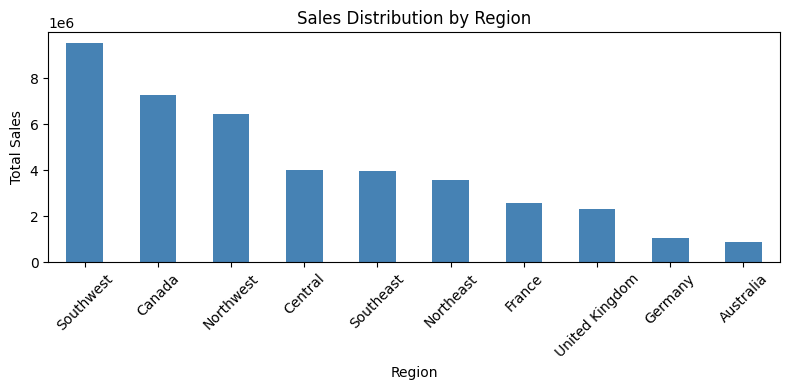


Top Performing Regions:
salesregion
Southwest    9.517869e+06
Canada       7.285031e+06
Northwest    6.456252e+06
Central      4.004239e+06
Southeast    3.951639e+06
Name: salesamount, dtype: float64

Sales by Region and Product Category:
category        Accessories         Bikes     Clothing    Components
salesregion                                                         
Australia        15665.0821  7.021084e+05   26453.6424  1.167587e+05
Canada           67900.7418  5.789830e+06  208920.6261  1.218380e+06
Central          24238.2453  3.350603e+06   83826.1954  5.455706e+05
France           27382.6729  1.960982e+06   70939.0706  5.230951e+05
Germany          19727.0830  7.869655e+05   40401.2923  1.843711e+05
Northeast        28232.5398  2.888414e+06   88527.5685  5.816098e+05
Northwest        31571.5111  5.298456e+06  107356.8144  1.018868e+06
Southeast        24217.0244  3.301330e+06   84094.2833  5.419977e+05
Southwest        60319.5916  7.729911e+06  202270.1457  1.525369e+06
U

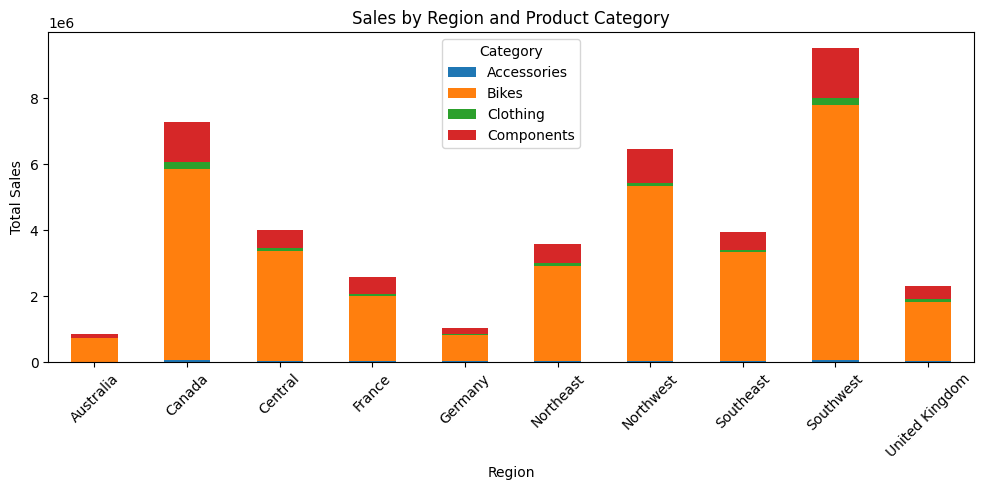


Data aggregation completed successfully!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
url = "https://raw.githubusercontent.com/shizakhalidi/Retail-Sales-Data-EDA/refs/heads/main/Retail.csv"
df = pd.read_csv(url)

# 1-2. Load and explore
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nFirst 5 rows:\n", df.head())

print("\nData types:\n", df.dtypes)

print("\nMissing values:\n", df.isnull().sum())

# Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("\nCleaned columns:", df.columns.tolist())

# 3. Relevant variables
print("\nRelevant variables:")
print(["salesregion", "salesamount", "category"])

# Clean sales amount
df["salesamount"] = pd.to_numeric(
    df["salesamount"],
    errors="coerce"
)

df = df.dropna(
    subset=["salesregion", "salesamount"]
)

# 4. Total sales by region
region_sales = (
    df.groupby("salesregion")["salesamount"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTotal Sales by Region:")
print(region_sales)

# 5. Sales distribution by region
plt.figure(figsize=(8, 4))

region_sales.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Sales Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Top-performing regions
print("\nTop Performing Regions:")
print(region_sales.head())

# 7. Sales by region and category
category_sales = df.pivot_table(
    index="salesregion",
    columns="category",
    values="salesamount",
    aggfunc="sum",
    fill_value=0
)

print("\nSales by Region and Product Category:")
print(category_sales)

# 8. Stacked bar plot
category_sales.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Sales by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

print("\nData aggregation completed successfully!")